<a href="https://colab.research.google.com/github/mixxr/aem-cli/blob/master/exercises/lesson05/Feature_Engineering_Pipelines_and_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature Engineering, Pipelines, Model Evaluation, and Feature Importance (Interpretability)

5-Fold CV ROC-AUC: 0.986 (+/- 0.017)
Test Set ROC-AUC: 0.994

              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



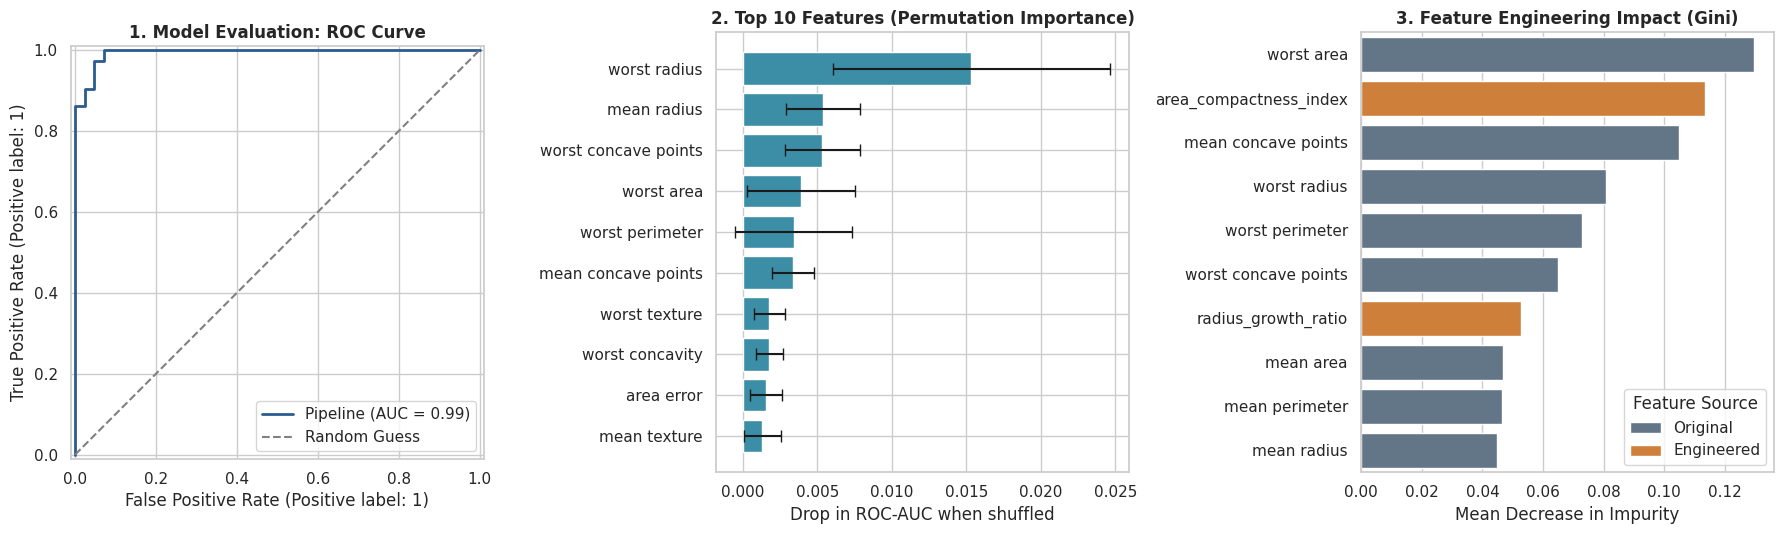

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, roc_auc_score, RocCurveDisplay

# Set visual style for clean educational plots
sns.set_theme(style="whitegrid", context="notebook")

# 1. Load a real biological dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target  # 0 = malignant, 1 = benign

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Define custom Feature Engineering inside a function
def engineer_biological_features(df):
    df = df.copy()
    df["radius_growth_ratio"] = df["worst radius"] / (df["mean radius"] + 1e-5)
    df["area_compactness_index"] = df["mean area"] * df["mean compactness"]
    return df

feature_engineer = FunctionTransformer(engineer_biological_features)

# 3. Build the Machine Learning Pipeline
pipeline = Pipeline([
    ("feat_eng", feature_engineer),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=100, random_state=42))
])

# 4. Model Evaluation
cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring="roc_auc")
print(f"5-Fold CV ROC-AUC: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

print(f"Test Set ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}\n")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# 5. Compute Feature Importances
# A) Permutation Importance (on original input features)
perm_importance = permutation_importance(
    pipeline, X_test, y_test, n_repeats=15, random_state=42, scoring="roc_auc"
)
perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_importance.importances_mean,
    "Std": perm_importance.importances_std
}).sort_values(by="Importance", ascending=False).head(10)

# B) Internal Random Forest Gini Importance (includes engineered features)
X_train_eng = pipeline.named_steps["feat_eng"].transform(X_train)
rf_model = pipeline.named_steps["classifier"]

engineered_names = ["radius_growth_ratio", "area_compactness_index"]
tree_df = pd.DataFrame({
    "Feature": X_train_eng.columns,
    "Importance": rf_model.feature_importances_,
    "Type": ["Engineered" if col in engineered_names else "Original" for col in X_train_eng.columns]
}).sort_values(by="Importance", ascending=False).head(10)

# 6. Create Educational Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Plot 1: ROC Curve (Model Evaluation)
RocCurveDisplay.from_estimator(
    pipeline, X_test, y_test, ax=axes[0], color="#2b5c8f", lw=2
)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
axes[0].set_title("1. Model Evaluation: ROC Curve", fontsize=12, fontweight="bold")
axes[0].legend(loc="lower right")

# Plot 2: Permutation Importance (Model-Agnostic Interpretability)
axes[1].barh(
    perm_df["Feature"][::-1],
    perm_df["Importance"][::-1],
    xerr=perm_df["Std"][::-1],
    color="#3b8ea5",
    capsize=4
)
axes[1].set_title("2. Top 10 Features (Permutation Importance)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Drop in ROC-AUC when shuffled")

# Plot 3: Gini Importance highlighting Engineered Features
palette = {"Engineered": "#e67e22", "Original": "#5c768d"}
sns.barplot(
    data=tree_df,
    x="Importance",
    y="Feature",
    hue="Type",
    dodge=False,
    palette=palette,
    ax=axes[2]
)
axes[2].set_title("3. Feature Engineering Impact (Gini)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Mean Decrease in Impurity")
axes[2].set_ylabel("")
axes[2].legend(title="Feature Source", loc="lower right")

plt.tight_layout()
plt.show()


## Observations
- Preventing Data Leakage with Pipelines. Putting FunctionTransformer and StandardScaler inside a Pipeline ensures that feature transformations and scaling parameters are learned strictly on the training folds during cross-validation, never leaking test set statistics.
- Domain-Driven Feature Engineering. Instead of throwing raw measurements at the model, creating radius_growth_ratio captures biological asymmetry between the average cell size and the largest abnormal cells.
- Two Ways to Measure Importance.
	- Permutation Importance (Model-Agnostic). Measures how much the test ROC-AUC drops when a feature's values are shuffled. It is reliable because it evaluates real predictive impact on unseen data.
	- Gini / Impurity Importance (Model-Specific). Extracted directly from `pipeline.named_steps["classifier"]`. This lets students see whether their newly engineered features ranked among the top predictors.
- Metrics Beyond Accuracy. Using ROC-AUC and a Classification Report (Precision and Recall) shows why medical/biological predictions require tracking false negatives rather than relying on accuracy alone.


## Plots
- Plot 1 (ROC Curve). Visualizes the trade-off between True Positive Rate (Sensitivity) and False Positive Rate across thresholds, reinforcing why single-number accuracy is insufficient in medical diagnostics.
- Plot 2 (Permutation Importance). Shows which input features cause the largest drop in test performance when randomized, including error bars (`xerr`) to demonstrate variance across repeats.
- Plot 3 (Feature Engineering Impact). Color-codes engineered features in orange against original features in slate blue, giving students immediate visual proof of whether their domain-specific variables (`area_compactness_index` and `radius_growth_ratio`) ranked among the top predictors.